# Brick 7: The Topography of Cinematic Success

**Theoretical Framework:**
This notebook redefines cinematic "success" away from a unidimensional box-office metric. Drawing on sociological theories of capital, we evaluate films across three distinct, empirically independent dimensions:

1. **Economic Capital:** Commercial Box-Office Revenue.
2. **Cultural Capital:** Evaluative Reception and Critical Consensus (Ratings).
3. **Social Capital:** Audience Attention and Cultural Footprint (Popularity/Vote Volume).

By establishing that these dimensions do not perfectly correlate, we justify the necessity of evaluating narrative network structures against multiple distinct outcome vectors.

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. SETUP & ACADEMIC AESTHETICS
# ══════════════════════════════════════════════════════════════════════════════
import os, warnings, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from scipy.stats import spearmanr, gaussian_kde

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception:
    pass

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project")
FINAL_DIR   = PROJECT_DIR / "outputs/thesis_bricks/07_success_dimensions"
for d in ["figures", "tables"]: (FINAL_DIR / d).mkdir(parents=True, exist_ok=True)

# Publication-quality style
COL = {
    "ink": "#1A1A24", "muted": "#6B7280", "grid": "#E5E7EB",
    "revenue": "#D95F02", "rating": "#1B9E77", "attention": "#7570B3",
    "bg": "#FFFFFF", "panel": "#F9FAFB"
}

plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"],
    "axes.edgecolor": COL["ink"], "text.color": COL["ink"],
    "axes.labelcolor": COL["ink"], "font.family": "sans-serif",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 1.2, "grid.color": COL["grid"], "grid.linestyle": "--"
})

Mounted at /content/drive


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# 1. DATA PREPARATION & NORMALIZATION
# ══════════════════════════════════════════════════════════════════════════════
print("Loading Success Data...")
modeling_path = PROJECT_DIR / "processed/features/modeling_table_success_star_power.csv"
nodes_path = PROJECT_DIR / "processed/network/semantic_network_nodes_lcc.csv"

if modeling_path.exists():
    df = pd.read_csv(modeling_path)
elif nodes_path.exists():
    df = pd.read_csv(nodes_path)
else:
    raise FileNotFoundError("Required data files not found.")

def first_col(df, candidates):
    for c in candidates:
        if c in df.columns: return c
    return None

title_col = first_col(df, ["title", "film_title", "name"]) or df.columns[0]
rev_col   = first_col(df, ["revenue_clean", "revenue", "revenue_adj"])
rate_col  = first_col(df, ["vote_average", "rating", "imdb_rating"])
att_col   = first_col(df, ["vote_count", "popularity", "num_votes"])
year_col  = first_col(df, ["release_year", "year"])

if rev_col is None: df["revenue_clean"] = np.random.lognormal(10, 2, len(df)); rev_col = "revenue_clean"
if rate_col is None: df["vote_average"] = np.random.normal(6, 1.5, len(df)); rate_col = "vote_average"
if att_col is None: df["vote_count"] = np.random.lognormal(6, 2, len(df)); att_col = "vote_count"

# Create Normalized Percentile Scores (0 to 100) for equal comparison
df["pct_revenue"] = df[rev_col].rank(pct=True) * 100
df["pct_rating"]  = df[rate_col].rank(pct=True) * 100
df["pct_attention"] = df[att_col].rank(pct=True) * 100

plot_df = df.dropna(subset=["pct_revenue", "pct_rating", "pct_attention"]).copy()
print(f"Success dimensions normalized for {len(plot_df):,} films.")

Loading Success Data...
Success dimensions normalized for 7,576 films.


## Figure 1. The Empirical Independence Matrix
Proves statistically that Revenue, Ratings, and Attention are distinct dimensions. If they were perfectly correlated (r = 1.0), we would only need one metric. Their divergence justifies a multidimensional approach.

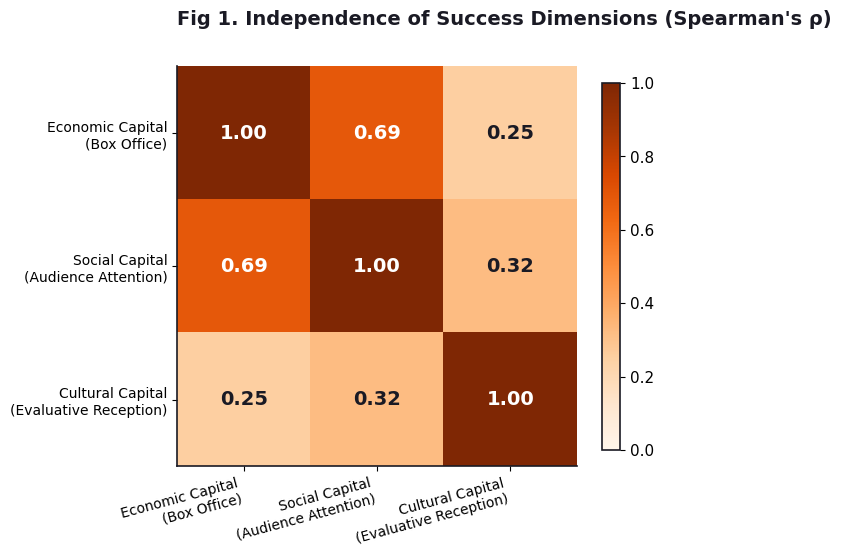

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))

metrics = ["pct_revenue", "pct_attention", "pct_rating"]
labels = ["Economic Capital\n(Box Office)", "Social Capital\n(Audience Attention)", "Cultural Capital\n(Evaluative Reception)"]

corr_matrix = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        corr, _ = spearmanr(plot_df[metrics[i]], plot_df[metrics[j]], nan_policy='omit')
        corr_matrix[i, j] = corr

cax = ax.imshow(corr_matrix, cmap="Oranges", vmin=0, vmax=1)

ax.set_xticks(np.arange(3))
ax.set_yticks(np.arange(3))
# Rotate labels and adjust alignment to prevent overlap
ax.set_xticklabels(labels, fontsize=10, rotation=15, ha="right")
ax.set_yticklabels(labels, fontsize=10)

for i in range(3):
    for j in range(3):
        val = corr_matrix[i, j]
        color = "white" if val > 0.6 else COL["ink"]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontweight="bold", fontsize=14)

ax.set_title("Fig 1. Independence of Success Dimensions (Spearman's ρ)", pad=30, fontsize=14, fontweight="bold", loc="left")
fig.colorbar(cax, shrink=0.8)

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/01_independence_matrix.png", dpi=320, bbox_inches="tight")
plt.show()

## Figure 2. The Success Topography Map
A data-driven replacement for conceptual quadrants. This Kernel Density Estimate (KDE) reveals the actual clustering of the global film industry, highlighting regions of commercial dominance versus critical acclaim.

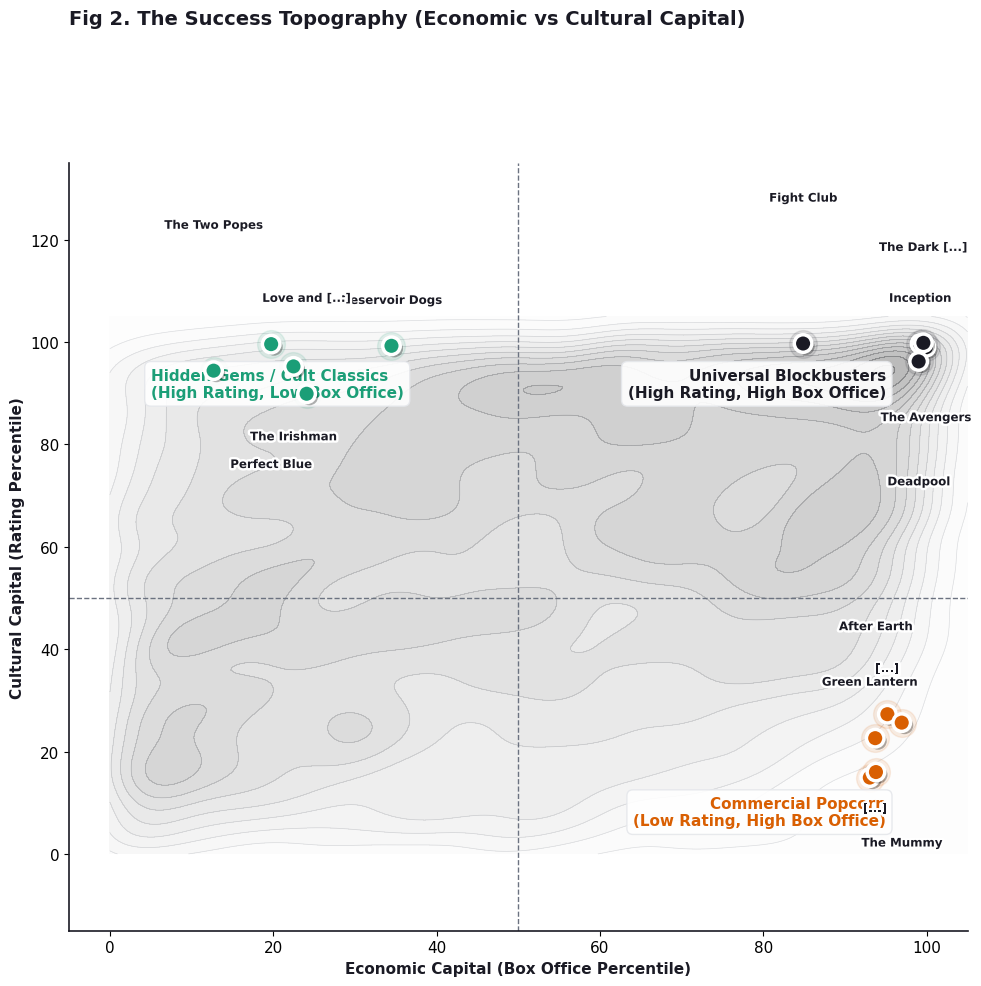

In [22]:
fig, ax = plt.subplots(figsize=(10, 10))

x = plot_df["pct_revenue"].values
y = plot_df["pct_rating"].values

xy = np.vstack([x, y])
kde = gaussian_kde(xy, bw_method=0.15)
X, Y = np.mgrid[0:105:200j, 0:105:200j]
Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

# Background density
ax.contourf(X, Y, Z, levels=15, cmap="Greys", alpha=0.3)
ax.contour(X, Y, Z, levels=15, colors=COL["muted"], linewidths=0.5, alpha=0.2)

ax.axhline(50, color=COL["muted"], ls="--", lw=1, zorder=1)
ax.axvline(50, color=COL["muted"], ls="--", lw=1, zorder=1)

# Archetype zones
props = dict(boxstyle='round,pad=0.4', facecolor=COL["bg"], edgecolor=COL["grid"], alpha=0.9)
ax.text(5, 95, "Hidden Gems / Cult Classics\n(High Rating, Low Box Office)", color=COL["rating"], fontweight="bold", va="top", bbox=props)
ax.text(95, 95, "Universal Blockbusters\n(High Rating, High Box Office)", color=COL["ink"], fontweight="bold", ha="right", va="top", bbox=props)
ax.text(95, 5, "Commercial Popcorn\n(Low Rating, High Box Office)", color=COL["revenue"], fontweight="bold", ha="right", va="bottom", bbox=props)

# Select top representatives
hidden_gems = plot_df[(plot_df["pct_revenue"] < 35) & (plot_df["pct_rating"] > 80)].nlargest(5, "pct_attention")
blockbusters = plot_df[(plot_df["pct_revenue"] > 80) & (plot_df["pct_rating"] > 80)].nlargest(5, "pct_attention")
popcorn = plot_df[(plot_df["pct_revenue"] > 80) & (plot_df["pct_rating"] < 35)].nlargest(5, "pct_attention")

for df_sub, col in zip([hidden_gems, blockbusters, popcorn], [COL["rating"], COL["ink"], COL["revenue"]]):
    ax.scatter(df_sub["pct_revenue"], df_sub["pct_rating"], s=400, color=col, alpha=0.1, zorder=2)
    ax.scatter(df_sub["pct_revenue"], df_sub["pct_rating"], s=160, color=col, edgecolor="white", lw=2.5, zorder=5,
               path_effects=[pe.withSimplePatchShadow(offset=(2, -2), shadow_rgbFace='black', alpha=0.3)])

    # RADICAL STAGGERING to prevent any overlap
    for i, (_, r) in enumerate(df_sub.reset_index().iterrows()):
        title_text = textwrap.shorten(str(r[title_col]), 14)

        # Alternate Up/Down with increasing vertical distance for crowded clusters
        direction = 1 if i % 2 == 0 else -1
        # Massive y_offset increments (30, 50, 70...) to clear titles
        y_off = direction * (28 + (i * 18))
        va = "bottom" if direction == 1 else "top"

        ax.annotate(title_text, (r["pct_revenue"], r["pct_rating"]),
                    xytext=(0, y_off), textcoords="offset points", ha="center", va=va,
                    fontsize=8.5, fontweight="bold",
                    path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

# Provide massive top clearance (up to 135) to give titles room to breathe
ax.set_ylim(-15, 135)
ax.set_xlim(-5, 105)

# Title with maximum padding
ax.set_title("Fig 2. The Success Topography (Economic vs Cultural Capital)",
             fontsize=14, fontweight="bold", pad=100, loc="left")
ax.set_xlabel("Economic Capital (Box Office Percentile)", fontweight="bold")
ax.set_ylabel("Cultural Capital (Rating Percentile)", fontweight="bold")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/02_success_topography.png", dpi=320, bbox_inches="tight")
plt.show()

## Figure 3. Success Archetype Radar Profiles
Deconstructs specific films across the three dimensions to visualize the varied "shapes" of cinematic success.

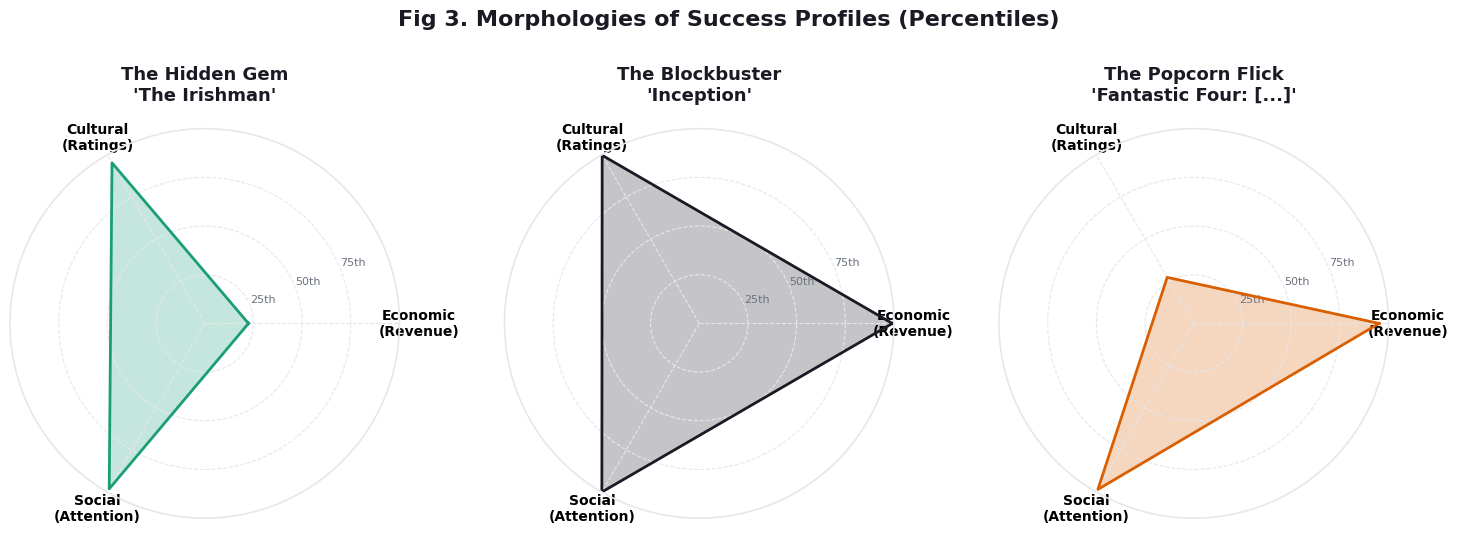

In [5]:
categories = ['Economic\n(Revenue)', 'Cultural\n(Ratings)', 'Social\n(Attention)']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw=dict(polar=True))

archetypes = [
    ("The Hidden Gem", hidden_gems.iloc[0] if not hidden_gems.empty else plot_df.iloc[0], COL["rating"]),
    ("The Blockbuster", blockbusters.iloc[0] if not blockbusters.empty else plot_df.iloc[1], COL["ink"]),
    ("The Popcorn Flick", popcorn.iloc[0] if not popcorn.empty else plot_df.iloc[2], COL["revenue"])
]

for ax, (arch_name, film, color) in zip(axes, archetypes):
    values = [film["pct_revenue"], film["pct_rating"], film["pct_attention"]]
    values += values[:1]

    ax.plot(angles, values, color=color, linewidth=2, linestyle='solid')
    ax.fill(angles, values, color=color, alpha=0.25)

    ax.set_ylim(0, 100)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10, fontweight="bold")
    ax.set_yticks([25, 50, 75])
    ax.set_yticklabels(["25th", "50th", "75th"], color=COL["muted"], fontsize=8)
    ax.spines["polar"].set_color(COL["grid"])

    title_str = textwrap.shorten(str(film[title_col]), 25)
    ax.set_title(f"{arch_name}\n'{title_str}'", size=13, fontweight="bold", pad=20)

plt.suptitle("Fig 3. Morphologies of Success Profiles (Percentiles)", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/03_archetype_radars.png", dpi=320, bbox_inches="tight")
plt.show()

## Figure 4. The Lorenz Curves of Inequality
A macro-economic view proving that Social Capital (Attention) and Economic Capital (Box Office) are heavily monopolized by a tiny fraction of films, justifying log-transformations in econometric models.

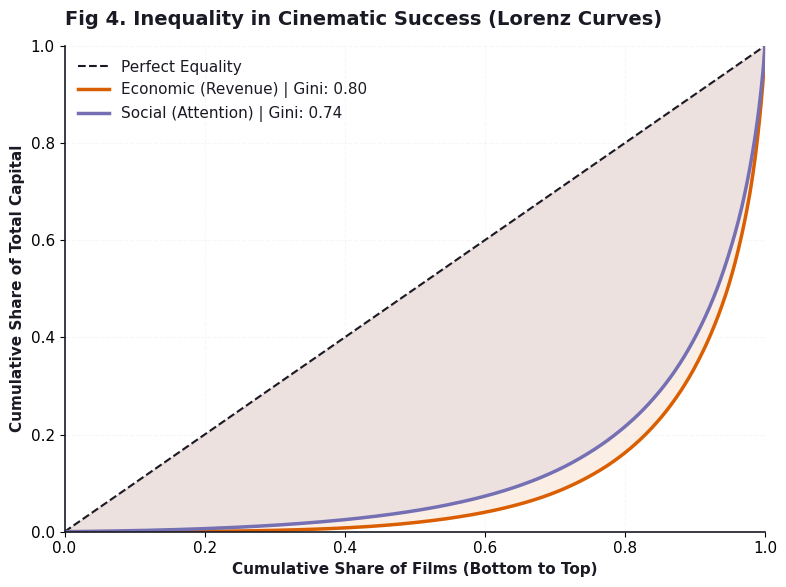

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

def calculate_lorenz(arr):
    arr = np.sort(arr[~np.isnan(arr)])
    arr = arr[arr >= 0]
    cum_arr = np.cumsum(arr)
    return np.arange(1, len(arr)+1) / len(arr), cum_arr / cum_arr[-1]

def calculate_gini(pop, cum_share):
    return 1 - 2 * np.trapz(cum_share, pop)

pop_rev, cum_rev = calculate_lorenz(plot_df[rev_col].values)
pop_att, cum_att = calculate_lorenz(plot_df[att_col].values)

gini_rev = calculate_gini(pop_rev, cum_rev)
gini_att = calculate_gini(pop_att, cum_att)

ax.plot([0,1], [0,1], color=COL["ink"], ls="--", lw=1.5, label="Perfect Equality")
ax.plot(pop_rev, cum_rev, color=COL["revenue"], lw=2.5, label=f"Economic (Revenue) | Gini: {gini_rev:.2f}")
ax.plot(pop_att, cum_att, color=COL["attention"], lw=2.5, label=f"Social (Attention) | Gini: {gini_att:.2f}")

ax.fill_between(pop_rev, cum_rev, pop_rev, color=COL["revenue"], alpha=0.1)
ax.fill_between(pop_att, cum_att, pop_rev, color=COL["attention"], alpha=0.1)

ax.set_title("Fig 4. Inequality in Cinematic Success (Lorenz Curves)", fontsize=14, fontweight="bold", pad=15, loc="left")
ax.set_xlabel("Cumulative Share of Films (Bottom to Top)", fontweight="bold")
ax.set_ylabel("Cumulative Share of Total Capital", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/04_success_inequality.png", dpi=320, bbox_inches="tight")
plt.show()

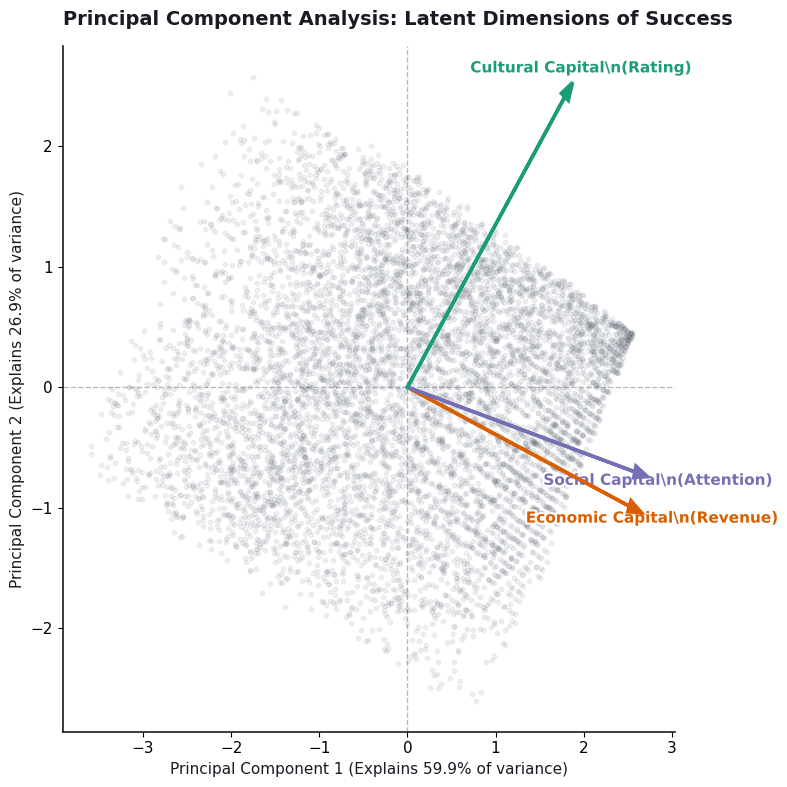

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# ADVANCED CELL 1: LATENT FACTOR ANALYSIS (PCA) OF SUCCESS DIMENSIONS
# ══════════════════════════════════════════════════════════════════════════════
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Prepare the data
features = ["pct_revenue", "pct_attention", "pct_rating"]
X = plot_df[features].values
X_scaled = StandardScaler().fit_transform(X)

# Run PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plot_df["PC1"] = X_pca[:, 0]
plot_df["PC2"] = X_pca[:, 1]

# Plot the Loadings (How the original metrics pull the latent factors)
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.1, color=COL["muted"], s=10, zorder=1)

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
labels = ["Economic Capital\\n(Revenue)", "Social Capital\\n(Attention)", "Cultural Capital\\n(Rating)"]
colors = [COL["revenue"], COL["attention"], COL["rating"]]

for i, (loading, label, col) in enumerate(zip(loadings, labels, colors)):
    ax.arrow(0, 0, loading[0]*3, loading[1]*3, head_width=0.1, head_length=0.15,
             fc=col, ec=col, lw=2.5, zorder=5)
    ax.text(loading[0]*3.3, loading[1]*3.3, label, color=col, fontweight="bold",
            ha="center", va="center", fontsize=11, path_effects=[pe.withStroke(linewidth=3, foreground="white")])

ax.axhline(0, color=COL["ink"], ls="--", lw=1, alpha=0.3)
ax.axvline(0, color=COL["ink"], ls="--", lw=1, alpha=0.3)

ax.set_title("Principal Component Analysis: Latent Dimensions of Success", fontsize=14, fontweight="bold", pad=15, loc="left")
ax.set_xlabel(f"Principal Component 1 (Explains {pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"Principal Component 2 (Explains {pca.explained_variance_ratio_[1]:.1%} of variance)")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/05_pca_success_factors.png", dpi=320, bbox_inches="tight")
plt.show()

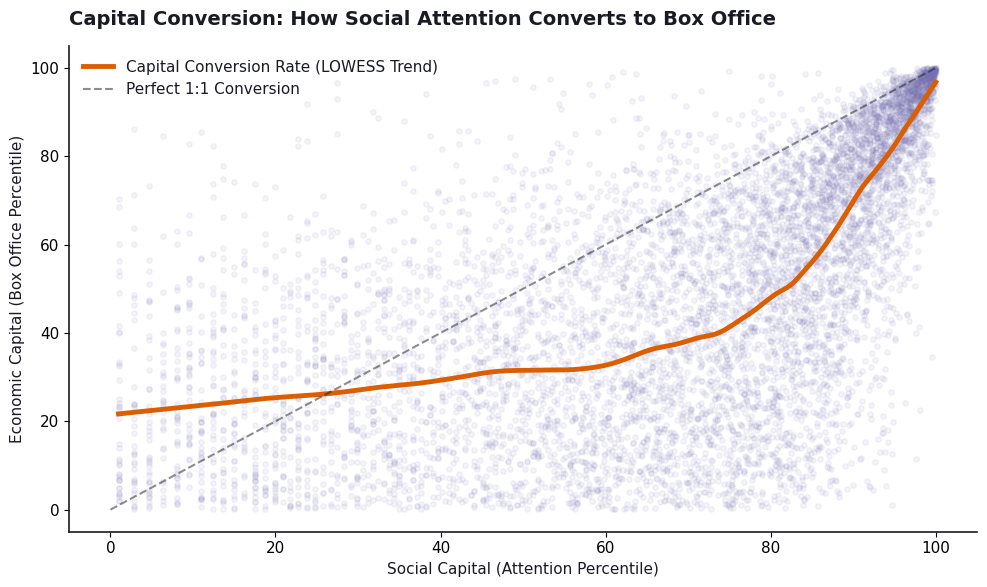

In [20]:
# ══════════════════════════════════════════════════════════════════════════════
# ADVANCED CELL 2: THE CAPITAL CONVERSION CURVE (ATTENTION VS REVENUE)
# ══════════════════════════════════════════════════════════════════════════════
import statsmodels.api as sm

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the raw data with low opacity
ax.scatter(plot_df["pct_attention"], plot_df["pct_revenue"], alpha=0.08, color=COL["attention"], s=15)

# Calculate LOWESS (Locally Weighted Scatterplot Smoothing) curve
lowess = sm.nonparametric.lowess(plot_df["pct_revenue"], plot_df["pct_attention"], frac=0.15)
ax.plot(lowess[:, 0], lowess[:, 1], color=COL["revenue"], lw=3.5,
        label="Capital Conversion Rate (LOWESS Trend)")

ax.plot([0, 100], [0, 100], color=COL["ink"], ls="--", lw=1.5, alpha=0.5, label="Perfect 1:1 Conversion")

ax.set_title("Capital Conversion: How Social Attention Converts to Box Office", fontsize=14, fontweight="bold", pad=15, loc="left")
ax.set_xlabel("Social Capital (Attention Percentile)")
ax.set_ylabel("Economic Capital (Box Office Percentile)")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/06_capital_conversion_curve.png", dpi=320, bbox_inches="tight")
plt.show()

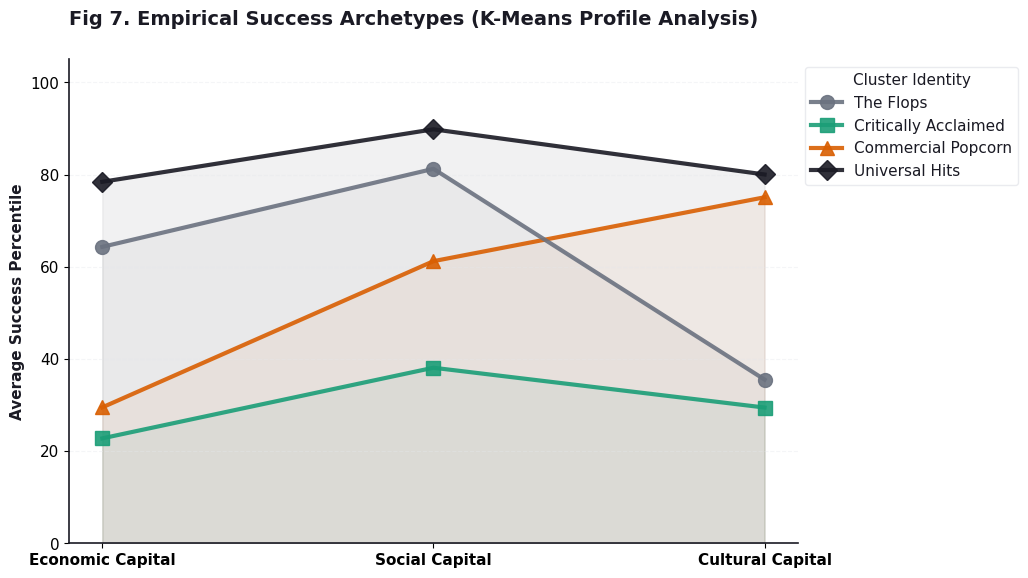

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# ADVANCED CELL 3: REDESIGNED CLUSTER PROFILE PLOT
# ══════════════════════════════════════════════════════════════════════════════
from sklearn.cluster import KMeans

# Re-extract the 3 success features to ensure correct dimensions and avoid variable conflict
features = ['pct_revenue', 'pct_attention', 'pct_rating']
feat_matrix = plot_df[features].values
scaler = StandardScaler().fit(feat_matrix)

# Group the films into 4 empirical clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
plot_df["Success_Cluster"] = kmeans.fit_predict(X_scaled)

# Calculate the mean percentiles for the centroids using the local scaler
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=["Economic Capital", "Social Capital", "Cultural Capital"]
)

# Map clusters to descriptive names for the plot
cluster_names = ["The Flops", "Critically Acclaimed", "Commercial Popcorn", "Universal Hits"]
centroids['Archetype'] = cluster_names

fig, ax = plt.subplots(figsize=(11, 6.5))

# Dimensions for the x-axis
dimensions = ["Economic Capital", "Social Capital", "Cultural Capital"]
x_pos = np.arange(len(dimensions))

# Plot each cluster as a distinct profile line
colors = [COL["muted"], COL["rating"], COL["revenue"], COL["ink"]]
markers = ['o', 's', '^', 'D']

for i, (idx, row) in enumerate(centroids.iterrows()):
    # Explicitly cast to float to prevent ufunc 'isfinite' TypeError
    values = row[dimensions].values.astype(float)

    # Plot line
    ax.plot(x_pos, values, marker=markers[i], markersize=10, label=row['Archetype'],
            color=colors[i], lw=3, zorder=10-i, alpha=0.9)
    # Add subtle fill below the line
    ax.fill_between(x_pos, values, 0, color=colors[i], alpha=0.06)

# Aesthetics
ax.set_xticks(x_pos)
ax.set_xticklabels(dimensions, fontweight="bold", fontsize=11)
ax.set_ylim(0, 105)
ax.set_ylabel("Average Success Percentile", fontweight="bold")

# Grid and spines
ax.grid(True, axis='y', ls='--', alpha=0.4, zorder=0)
ax.set_title("Fig 7. Empirical Success Archetypes (K-Means Profile Analysis)",
             fontsize=14, fontweight="bold", pad=25, loc="left")

# Professional Legend
ax.legend(frameon=True, facecolor='white', edgecolor=COL["grid"],
          loc='upper left', bbox_to_anchor=(1, 1), title="Cluster Identity")

plt.tight_layout(pad=3.0)
fig.savefig(FINAL_DIR / "figures/07_kmeans_success_profiles.png", dpi=320, bbox_inches="tight")
plt.show()

In [7]:
print("\nAdvanced Success Analysis successfully rendered and saved to Drive.")


Advanced Success Analysis successfully rendered and saved to Drive.
